## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
    .collect(engine="streaming")
)

In [5]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("total_imbalance_qty") * pl.col("entry_price"))
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("signed_dollar_imbalance") / pl.col("ADV"))
            .clip(-1,1)
        ).alias("signed_mean_imb_ratio"),
        (
            (pl.col("signed_dollar_imbalance") / pl.col("dollar_imbalance").mean().over(pl.col("date")))
        ).alias("signed_cross_imb_ratio"),
        # (
        #     ((pl.col("dollar_imbalance").rank().over(pl.col("date")) - pl.col("dollar_imbalance").rank().mean().over(pl.col("date"))) / pl.col("dollar_imbalance").rank().std().over(pl.col("date")))
        #     *pl.col("sign")
        # ).alias("zscore_rank_imb"),
        (
            ((pl.col("signed_dollar_imbalance").rank().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))) 
             / (pl.col("signed_dollar_imbalance").rank().max().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("zscore_rank_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
)

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,ADV,dollar_imbalance,sign,signed_dollar_imbalance,signed_mean_imb_ratio,signed_cross_imb_ratio,zscore_rank_imb,return_to_close
date,cat,str,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64
2025-06-11,"""AAL""","""A""",11.035,0.000906,11.06,9.7183e7,1.4006e6,-1,-1.4006e6,-0.014412,-0.509957,-0.604494,0.002266
2025-06-11,"""AAOI""","""B""",16.37,0.001221,16.32,1.4384e7,208340.99,1,208340.99,0.014484,0.075855,0.546067,-0.003054
2025-06-11,"""AAON""","""B""",75.78,0.001056,75.85,4.9410e7,565849.26,1,565849.26,0.011452,0.206019,0.629213,0.000924
2025-06-11,"""AAPL""","""A""",198.81,0.000201,198.78,2.2199e9,5.4598e7,-1,-5.4598e7,-0.024595,-19.878577,-0.988764,-0.000151
2025-06-11,"""AAXJ""","""N""",81.8,0.000122,81.88,2.4416e7,0.0,0,0.0,0.0,0.0,0.223596,0.000978
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ZG""","""N""",34.46,0.00029,34.1,1.4582e7,0.0,0,0.0,0.0,0.0,0.201671,-0.010447
2026-06-10,"""ZION""","""N""",65.56,0.000305,65.82,2.7290e7,0.0,0,0.0,0.0,0.0,0.201671,0.003966
2026-06-10,"""ZLAB""","""A""",17.3,0.000578,17.26,4.5611e6,1192938.8,-1,-1.1929e6,-0.261546,-0.205185,-0.484487,-0.002312


### Working on Forecasting

In [6]:
import sklearn
import statsmodels.api as sm

features = ["signed_mean_imb_ratio", "signed_cross_imb_ratio", "zscore_rank_imb"]

X = data[features].to_pandas()
y = data["return_to_close"].to_pandas()

model = sklearn.linear_model.Lasso(alpha=0.00001)
model.fit(X,y)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1e-05
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [7]:
print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f"{f} = {model.coef_[i]:,.10f}")

Model coefficients:

signed_mean_imb_ratio = 0.0021518252
signed_cross_imb_ratio = 0.0000068133
zscore_rank_imb = 0.0008106752


Background dataset has 214547 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=214547 when initializing the masker.
ExactExplainer explainer: 214548it [01:57, 1697.08it/s]                            


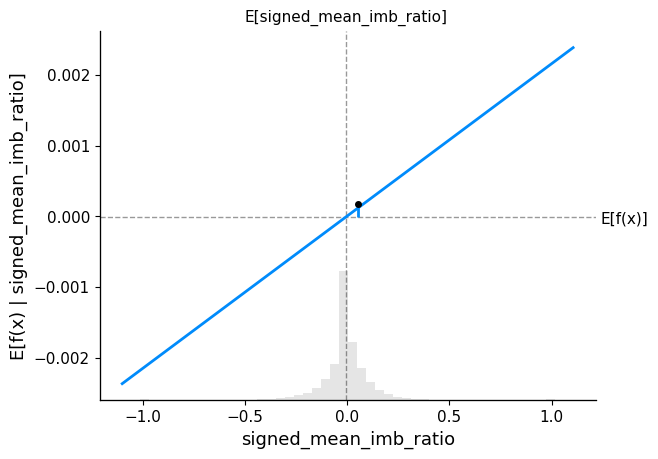

In [10]:
import shap

# compute the SHAP values for the linear model
explainer = shap.Explainer(model.predict, X)
shap_values = explainer(X)

# make a standard partial dependence plot
sample_ind = 20
shap.partial_dependence_plot(
    "zscore_rank_imb",
    model.predict,
    X,
    model_expected_value=True,
    feature_expected_value=True,
    ice=False,
    shap_values=shap_values[sample_ind : sample_ind + 1, :],
)

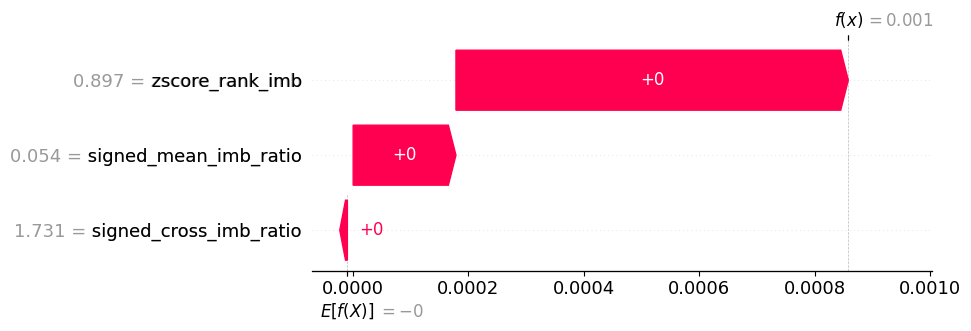

In [11]:
shap.plots.waterfall(shap_values[sample_ind])

### IC Study

In [36]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import spearmanr

# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
features = ["signed_mean_imb_ratio", "signed_cross_imb_ratio", "zscore_rank_imb"]

tscv = TimeSeriesSplit(n_splits=24, max_train_size=120, test_size=5)  # rolling ~120-day train window

fold_ics = []
for i, (train_d, test_d) in enumerate(tscv.split(dates)):
    train_dates = [dates[j] for j in train_d]
    test_dates  = [dates[j] for j in test_d]

    train = data.filter(pl.col("date").is_in(train_dates))
    test  = data.filter(pl.col("date").is_in(test_dates))

    model = Ridge(alpha=1e-1)
    # model = RandomForestRegressor()
    model.fit(train[features].to_numpy(), train["return_to_close"].to_numpy())

    # Forecast on test, then daily cross-sectional rank IC (Spearman), averaged.
    pred = test.with_columns(
        pl.Series("yhat", model.predict(test[features].to_numpy()))
    )
    daily_ic = (
        pred.group_by("date")
        .agg(
            pl.map_groups(
                exprs=["yhat", "return_to_close"],
                function=lambda s: spearmanr(s[0], s[1]).statistic,
                return_dtype=pl.Float64,
                returns_scalar=True,
            ).alias("ic")
        )
        .drop_nulls()
    )
    mean_ic = daily_ic["ic"].mean()
    fold_ics.append(mean_ic)
    print(f"fold {i}: train {train_dates[0]}..{train_dates[-1]} "
          f"({len(train_dates)}d) | test {test_dates[0]}..{test_dates[-1]} "
          f"({len(test_dates)}d) | mean daily IC = {mean_ic:+.4f}")

print(f"\nMean IC across folds: {np.mean(fold_ics):+.4f}  "
      f"(IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})")


fold 0: train 2025-06-24..2025-12-15 (120d) | test 2025-12-16..2025-12-22 (5d) | mean daily IC = +0.2188
fold 1: train 2025-07-01..2025-12-22 (120d) | test 2025-12-23..2025-12-31 (5d) | mean daily IC = +0.1588
fold 2: train 2025-07-10..2025-12-31 (120d) | test 2026-01-02..2026-01-08 (5d) | mean daily IC = +0.1830
fold 3: train 2025-07-17..2026-01-08 (120d) | test 2026-01-09..2026-01-15 (5d) | mean daily IC = +0.1954
fold 4: train 2025-07-24..2026-01-15 (120d) | test 2026-01-16..2026-01-23 (5d) | mean daily IC = +0.2154
fold 5: train 2025-07-31..2026-01-23 (120d) | test 2026-01-26..2026-01-30 (5d) | mean daily IC = +0.2257
fold 6: train 2025-08-07..2026-01-30 (120d) | test 2026-02-02..2026-02-06 (5d) | mean daily IC = +0.2315
fold 7: train 2025-08-14..2026-02-06 (120d) | test 2026-02-09..2026-02-13 (5d) | mean daily IC = +0.2251
fold 8: train 2025-08-21..2026-02-13 (120d) | test 2026-02-17..2026-02-23 (5d) | mean daily IC = +0.2434
fold 9: train 2025-08-28..2026-02-23 (120d) | test 2026